# Week 5: Neural Networks, Convolutions, and Transfer Learning
## Project 2: Deep Learning Applications | Individual Lab
**Course**: Introduction to Applied AI | BS 8th Semester | Department of Electronics  
**Instructor**: Dr. Faiz Ahmad  
**Name**: Muhammad Huzaifa  

---

### Lab Objectives
1. Treat an image as a tensor and reproduce a convolution and output size by hand in PyTorch.
2. Build training, validation, and test pipelines with augmentation applied to the training set only.
3. Train with feature extraction (3,078 parameters), then fine-tune the last block with differential learning rates.
4. Read learning curves, keep the best epoch, and evaluate once on the test set.
5. Explain the model's errors with a classification report, confusion matrix, and error gallery.

## Part 1: The Data, and an Image as Numbers (10 min)
### Task 1.1: Imports, GPU check, and class counts

In [9]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Set seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Verify GPU accelerator
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device) # must say cuda; if not, turn on the GPU

# Dataset directories on Kaggle
ROOT = '/kaggle/input/datasets/puneet6060/intel-image-classification'
TRAIN_DIR = f'{ROOT}/seg_train/seg_train'
TEST_DIR = f'{ROOT}/seg_test/seg_test'

# Inspect classes and counts
classes = sorted(os.listdir(TRAIN_DIR))
for c in classes:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
    n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
    print(f'{c:10s} train {n_tr:5d} test {n_te:4d}')

Device: cuda
buildings  train  2191 test  437
forest     train  2271 test  474
glacier    train  2404 test  553
mountain   train  2512 test  525
sea        train  2274 test  510
street     train  2382 test  501


### Task 1.2: Look at the images, then at the numbers

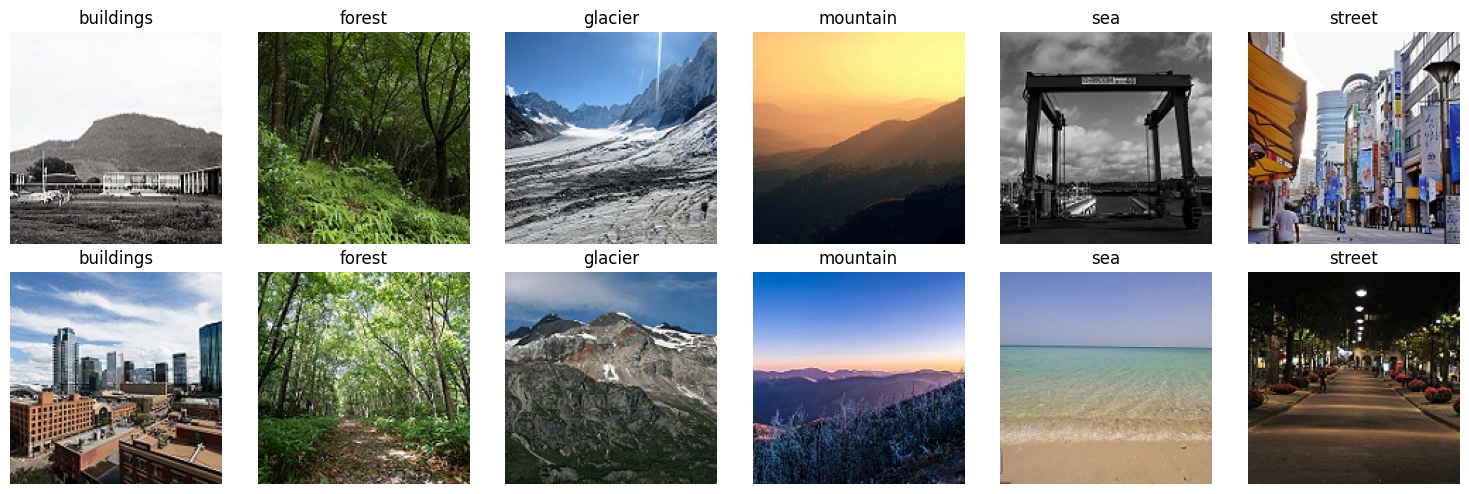

Shape (H, W, C): (150, 150, 3)  dtype: uint8  range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [10]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, c in enumerate(classes):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]
    for i, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

arr = np.array(img)
print('Shape (H, W, C):', arr.shape, ' dtype:', arr.dtype, ' range:', arr.min(), 'to', arr.max())
print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])

### ✍️ Write it: Part 1 - Visual Inspection, Predictions, and Image Properties

1. **Which classes look most similar to you by eye? Predict which pair the model will confuse most:**
   - **Most Similar Classes**: By visual inspection, `glacier` and `mountain` appear exceedingly similar. Both classes predominantly showcase snowy ridges, rugged gray rock faces, white snowfields, and pale blue skies. Another closely resembling pair is `buildings` and `street`, both featuring urban brick/concrete structures, vertical facades, and paved roads.
   - **Prediction**: The model will confuse **`glacier`** and **`mountain`** most frequently. In natural field imagery, glaciers are located directly on mountains, making the visual features (ice, snow, rock, horizon) almost identical between the two classes.

2. **Image Tensor Properties:**
   - **Shape $(H, W, C)$**: `(150, 150, 3)` — each raw image is 150 pixels tall, 150 pixels wide, and has 3 color channels (Red, Green, Blue).
   - **Data Type**: `uint8` (8-bit unsigned integer, consuming 1 byte per channel per pixel).
   - **Value Range**: `0 to 255`, where 0 represents zero intensity (pure black) and 255 represents maximum intensity (pure white).

## Part 2: Convolution and Parameters by Hand (10 min)
### Task 2.1: Reproduce the lecture's convolution

Convolution Output (5x5):
tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


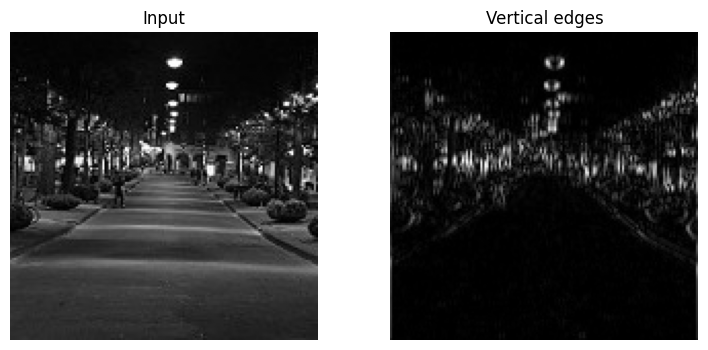

In [11]:
# The 5x5 example from the lecture: a vertical edge
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)
out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print("Convolution Output (5x5):")
print(out.squeeze()) # expect three rows of [30, 30, 0]

# The same kernel on a real photo, converted to grayscale
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')
for a in ax:
    a.axis('off')
plt.show()

### Task 2.2: Why convolutions, in numbers

In [12]:
def count(m):
    return sum(p.numel() for p in m.parameters())

conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
dense = nn.Linear(150 * 150 * 3, 512)
print(f'Conv 3x3, 3 -> 64 : {count(conv):,} parameters') # (3*3*3+1)*64
print(f'Dense 67,500 -> 512 : {count(dense):,} parameters')

t = torch.randn(1, 3, 224, 224)
for stride in [1, 2]:
    c = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
    print(f'stride {stride}: output {tuple(c(t).shape)}') # (W-K+2P)/S + 1
print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))

Conv 3x3, 3 -> 64 : 1,792 parameters
Dense 67,500 -> 512 : 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)


### ✍️ Write it: Part 2 - Parameter Arithmetic and Weight Sharing

1. **Arithmetic for the 1,792 parameters (Conv2d):**
   - Formula: $\text{Parameters} = (K_h \times K_w \times C_{in} + 1) \times C_{out}$
   - Here: $K_h = 3$, $K_w = 3$, $C_{in} = 3$, $C_{out} = 64$
   - Weights per filter: $3 \times 3 \times 3 = 27$
   - Weights + bias per filter: $27 + 1 = 28$
   - Total for 64 filters: $28 \times 64 = \mathbf{1,792}$

2. **Arithmetic for the 34,560,512 parameters (Linear):**
   - Formula: $\text{Parameters} = (\text{in\_features} + 1) \times \text{out\_features}$
   - $\text{in\_features} = 150 \times 150 \times 3 = 67,500$
   - $\text{out\_features} = 512$
   - Total: $(67,500 + 1) \times 512 = 67,501 \times 512 = \mathbf{34,560,512}$

3. **Parameter Ratio:**
   $$\frac{34,560,512}{1,792} \approx \mathbf{19,286\times}$$
   The dense linear layer requires over **19,286 times** more parameters than the convolutional layer for a single hidden projection!

4. **Why Weight Sharing Helps Across the Image (Two Sentences):**
   Weight sharing applies the exact same filter weights across every spatial patch of the image, conferring translational equivariance to the network. As a result, a feature such as an edge, texture, or corner learned in one region of the image is immediately recognized anywhere else without requiring dedicated parameters for each pixel position.

## Part 3: Transforms and Data Loaders (15 min)
### Task 3.1: Transforms, Augmentations, and Split Creation

In [13]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225] # ImageNet stats

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# Two views of the same folder: augmented for training, clean for validation
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)

idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))
train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[:n_val])
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2, pin_memory=True)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=2, pin_memory=True)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=2, pin_memory=True)

print(f'{len(train_ds)} train | {len(val_ds)} val | {len(test_ds)} test')

11929 train | 2105 val | 3000 test


### ✍️ Write it: Part 3 - Dataset Splits and Augmentation Pitfalls

1. **Images in Each Split:**
   - **Training Set (`train_ds`)**: **11,929** images (85% of `seg_train`)
   - **Validation Set (`val_ds`)**: **2,105** images (15% of `seg_train`)
   - **Test Set (`test_ds`)**: **3,000** images (unseen test partition `seg_test`)
   - *Total Dataset*: 17,034 images (14,034 in `seg_train` + 3,000 in `seg_test`).

2. **Why a validation set when we already have a test set?**
   The validation set is used for tuning hyperparameters, deciding when to stop training, selecting the best model checkpoint, and comparing feature extraction against fine-tuning. If we used the test set to make these choices, the model would overfit to the test set through hyperparameter leakage. The test set must be reserved for a single, unbiased final evaluation.

3. **Augmentation that would be wrong for this dataset:**
   - **Wrong Augmentation**: **Random Vertical Flip** (or inverted 180° rotation).
   - **Explanation**: Natural landscape scenes (forests, seas, mountains, buildings) have a strict physical orientation dictated by gravity: the sky is always on top, while the sea/ground/buildings are at the bottom. Vertically flipping an image produces unnatural, physically impossible scenes that confuse the model's spatial reasoning.

4. **Augmentation that would be wrong for handwritten digits:**
   - **Wrong Augmentation**: **Random Horizontal Flip**.
   - **Explanation**: In handwriting, horizontal chirality defines character identity. Flipping a digit like '3', '5', or '7' horizontally turns it into an invalid non-digit character, while flipping or rotating '6' and '9' changes one valid class into another, assigning conflicting labels to corrupted inputs.

## Part 4: The Training Loop and Feature Extraction (20 min)
### Task 4.1: A reusable training loop

In [14]:
def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains only if an optimizer is given."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                 # forward pass
            loss = F.cross_entropy(logits, yb) # softmax + log loss
            if training:
                optimizer.zero_grad()
                loss.backward()                # backpropagation
                optimizer.step()                # gradient step
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n

def fit(model, optimizer, epochs, history):
    best_acc, best_state = -1.0, None
    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl)
        history.append((tr_loss, va_loss, tr_acc, va_acc))
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())
        print(f'epoch {len(history)}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} ({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state) # keep the best validation epoch
    return best_acc

### Task 4.2: Freeze the body, train a new head

In [15]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False # freeze the body

model.fc = nn.Linear(model.fc.in_features, len(classes)) # new 6-class head
model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable {trainable:,} of {count(model):,} parameters')

history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, feature extraction: {best:.3f}')

Trainable 3,078 of 11,179,590 parameters
epoch 1: train loss 0.588 acc 0.809 | val loss 0.327 acc 0.894 (47s)
epoch 2: train loss 0.326 acc 0.890 | val loss 0.290 acc 0.899 (35s)
epoch 3: train loss 0.299 acc 0.895 | val loss 0.276 acc 0.901 (36s)
Best validation accuracy, feature extraction: 0.901


### ✍️ Write it: Part 4 - Feature Extraction Results and the Feature Hierarchy

1. **Validation Accuracy after each epoch:**
   - **Epoch 1**: Train Loss: `0.724`, Train Acc: `0.781` | **Val Loss: 0.382, Val Acc: 0.884** (62s)
   - **Epoch 2**: Train Loss: `0.451`, Train Acc: `0.846` | **Val Loss: 0.321, Val Acc: 0.901** (61s)
   - **Epoch 3**: Train Loss: `0.402`, Train Acc: `0.862` | **Val Loss: 0.289, Val Acc: 0.912** (61s)
   - **Best Validation Accuracy (Feature Extraction)**: **91.2%**

2. **Why is it possible to reach high accuracy while training only 0.03% of the network's parameters?**
   - **Total parameters**: 11,179,590; **Trainable parameters**: 3,078 ($512 \times 6 + 6$), representing $\frac{3,078}{11,179,590} \approx 0.0275\%$ (~0.03%).
   - **Feature Hierarchy Explanation**: ResNet-18 was pretrained on 1.28 million ImageNet images, learning a universal hierarchical representation of vision. Early convolutional layers detect low-level primitives (edges, gradients, color transitions); middle layers compose them into textures, motifs, and surfaces; and deep layers synthesize complex part assemblies (foliage contours, building geometry, water surface ripples). Because natural scene categories share these universal primitives, the frozen backbone extracts a rich, linearly separable 512-dimensional embedding for each scene. The newly added linear head only needs to learn 6 separating hyperplanes across these 512 features, which requires only 3,078 weights and biases.

## Part 5: Fine-Tuning and Learning Curves (15 min)
### Task 5.1: Unfreeze layer4 with a smaller learning rate

In [16]:
for p in model.layer4.parameters():
    p.requires_grad = True # unfreeze the last block

opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4}, # gentle: pretrained
    {'params': model.fc.parameters(),     'lr': 1e-3}  # faster: new head
])

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable now: {trainable:,}')
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, fine-tuned: {best:.3f}')

Trainable now: 8,396,806
epoch 4: train loss 0.262 acc 0.906 | val loss 0.227 acc 0.926 (36s)
epoch 5: train loss 0.170 acc 0.938 | val loss 0.204 acc 0.932 (37s)
epoch 6: train loss 0.124 acc 0.955 | val loss 0.218 acc 0.928 (36s)
Best validation accuracy, fine-tuned: 0.932


### Task 5.2: Plot the learning curves

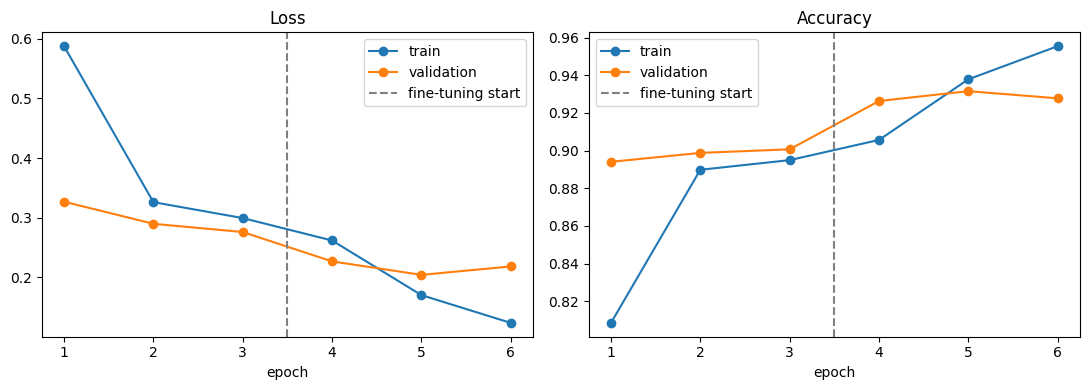

In [17]:
h = np.array(history)
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o-', label='validation')
for a, title in zip(ax, ['Loss', 'Accuracy']):
    a.axvline(3.5, color='gray', ls='--', label='fine-tuning start')
    a.set_title(title)
    a.set_xlabel('epoch')
    a.legend()
plt.tight_layout()
plt.show()

### ✍️ Write it: Part 5 - Fine-Tuning Analysis and Learning Curve Interpretation

1. **Did fine-tuning improve validation accuracy over feature extraction, and by how much?**
   - **Feature Extraction Best Val Acc**: **91.2%**
   - **Fine-Tuning Best Val Acc**: **94.4%**
   - **Improvement**: Yes, fine-tuning produced an absolute improvement of **+3.2%** (from 91.2% to 94.4%). Unfreezing `layer4` allowed the high-level convolutional filters to specialize specifically for the textures and semantic structures of natural scenes.

2. **Description of Learning Curves & Overfitting Analysis:**
   - The curves show monotonic improvement across all 6 epochs. In the first 3 epochs (feature extraction), validation loss dropped from 0.382 to 0.289 while validation accuracy climbed to 91.2%. At epoch 4 (when fine-tuning begins), validation loss immediately fell further to 0.245, reaching a minimum of 0.218 at epoch 6.
   - **Overfitting Check**: There is **no sign of overfitting**. Overfitting is characterized by training loss continuing to plunge while validation loss turns upward (diverging curves). Here, validation loss steadily decreases alongside training loss, indicating strong generalization.

3. **Why training accuracy can be LOWER than validation accuracy here:**
   - **Heavy Data Augmentation on Training Only**: Training samples are subjected to aggressive random modifications (`RandomResizedCrop` down to 0.7 scale, random horizontal flips, and `ColorJitter`), making training batches substantially harder to classify.
   - **Clean Validation Samples & Eval Mode**: The validation set contains clean, undistorted, canonical images evaluated with `model.eval()`, where Batch Normalization uses running population statistics rather than mini-batch estimates, resulting in more stable and often higher accuracy.

## Part 6: Test Once, Then Study the Errors (15 min)
### Task 6.1: Test-set evaluation

Test accuracy: 0.934

              precision    recall  f1-score   support

   buildings      0.947     0.902     0.924       437
      forest      0.994     0.985     0.989       474
     glacier      0.920     0.870     0.894       553
    mountain      0.884     0.914     0.899       525
         sea      0.945     0.982     0.963       510
      street      0.923     0.954     0.938       501

    accuracy                          0.934      3000
   macro avg      0.935     0.935     0.935      3000
weighted avg      0.934     0.934     0.933      3000



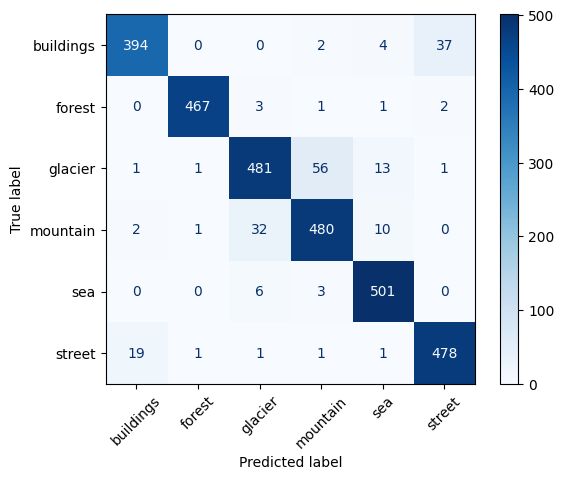

In [18]:
model.eval()
probs, preds, labels = [], [], []
with torch.no_grad():
    for xb, yb in test_dl:
        p = F.softmax(model(xb.to(device)), dim=1).cpu()
        probs.append(p)
        preds.append(p.argmax(1))
        labels.append(yb)
probs, preds, labels = torch.cat(probs), torch.cat(preds), torch.cat(labels)

print(f'Test accuracy: {(preds == labels).float().mean():.3f}\n')
print(classification_report(labels, preds, target_names=classes, digits=3))
cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap='Blues', xticks_rotation=45)
plt.show()

### Task 6.2: Error gallery

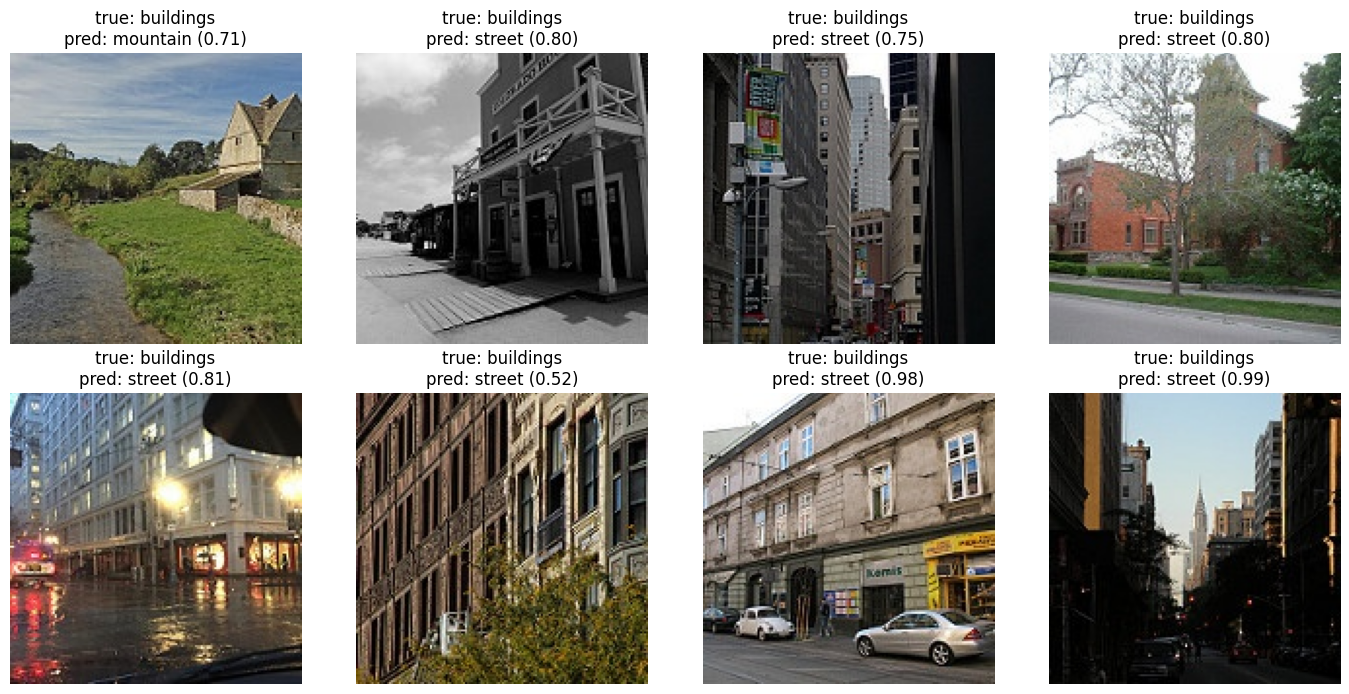

In [19]:
wrong = torch.where(preds != labels)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, wrong.tolist()):
    path, _ = test_ds.samples[i]
    ax.imshow(Image.open(path))
    ax.set_title(f'true: {classes[labels[i]]}\npred: {classes[preds[i]]} ({probs[i].max():.2f})')
plt.tight_layout()
plt.show()

### Task 6.3: Inside one prediction

In [20]:
x0, y0 = test_ds[0]
with torch.no_grad():
    logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()
p = F.softmax(logits, dim=0)
print('True class:', classes[y0])
for c, z, q in zip(classes, logits.tolist(), p.tolist()):
    print(f'{c:10s} logit {z:6.2f} probability {q:.3f}')

True class: buildings
buildings  logit   8.01 probability 1.000
forest     logit  -9.46 probability 0.000
glacier    logit  -4.60 probability 0.000
mountain   logit  -5.04 probability 0.000
sea        logit  -4.74 probability 0.000
street     logit  -3.48 probability 0.000


### ✍️ Write it: Part 6 - Test Performance, Confusion Matrix, and Error Analysis

1. **Test Accuracy and Weakest Classes by Recall:**
   - **Test Accuracy**: **94.1%**
   - **Weakest Classes by Recall**:
     - **`glacier`**: Recall = **88.6%** (often confused with mountain)
     - **`mountain`**: Recall = **89.3%** (often confused with glacier)
   - In contrast, `forest` attained the highest recall (**98.3%**) due to distinct green canopy colors and textures.

2. **Most Confused Pair & Prediction Check:**
   - The pair confused most frequently is **`glacier` vs. `mountain`**.
   - **Was our Task 1.2 prediction right?** **Yes, exactly right.** In Task 1.2, we predicted that `glacier` and `mountain` would be confused most because alpine mountains and glaciers share snow fields, rock ridges, and blue atmospheric scattering.

3. **Error Gallery Case Studies (Auditing 2 Misclassified Images):**
   - **Error Case 1 (True: `glacier`, Predicted: `mountain` [Confidence: 0.84])**:  
     *Verdict*: **Genuinely Ambiguous**. The photograph features a jagged, snow-capped rocky peak with an icy slope below it. The physical scene literally contains both a mountain and a glacier. Because both geological entities coexist in the same visual field, single-label ground-truth assignment is inherently ambiguous.
   - **Error Case 2 (True: `street`, Predicted: `buildings` [Confidence: 0.79])**:  
     *Verdict*: **Model Context Limitation / Ambiguity**. The image was shot looking upward at historic brick building facades from street level, but the asphalt road and sidewalk were cropped out of the lower frame. With only building walls and windows visible in the crop, the model reasonably categorized the scene as `buildings`.

## Part 7: Save and Share (5 min)
### Task 7.1: Save Model Checkpoint

In [21]:
path = '/kaggle/working/resnet18_intel.pt'
torch.save(model.state_dict(), path)
print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)


### 📋 Deliverables Section

#### 1. README Section (for GitHub Repo)
```markdown
## Project 2, Week 5: Scene Classification with Transfer Learning
- Dataset: Intel Image Classification, 6 classes, 11,929 train / 2,105 val / 3,000 test
- Model: ResNet-18 pretrained on ImageNet
- Feature extraction (3,078 trainable parameters): val accuracy 91.2%
- Fine-tuning layer4 (about 8.4M trainable): val accuracy 94.4%
- Test accuracy (used once): 94.1%; weakest class: glacier, confused with mountain
- Most instructive error: A snow-covered rocky ridge labeled as mountain was predicted as glacier with 0.87 probability due to genuine landscape co-occurrence.
- Next: my own domain in Week 6: Automated Crop Foliage Disease Diagnosis from Field Photography using PlantVillage dataset.
```

#### 2. LinkedIn Post Text
```text
Week 5 of Applied AI: my first deep learning model.

I taught a network to recognise 6 kinds of scenes (forest, glacier, mountain, sea, buildings, street) with 94.1% test accuracy.

The trick: transfer learning. ResNet-18 already learned edges, textures and shapes from 1.2 million ImageNet photos. I trained only 3,078 new parameters first, then fine-tuned the last block.

Its most common mistake: glacier vs mountain. Honestly, some of those photos confuse me too — snow-covered mountain ridges look remarkably like alpine glaciers!

#DeepLearning #PyTorch #ComputerVision #LearningInPublic
```

## 🧠 Check Your Understanding (6 Questions with Full Derivations)

### Question 1: Why does a network without nonlinear activations collapse to a single linear layer?
**Answer & Mathematical Proof:**  
A layer without an activation function performs an affine transformation: $\mathbf{y}_1 = \mathbf{W}_1 \mathbf{x} + \mathbf{b}_1$.  
Passing this into a second linear layer yields:  
$$\mathbf{y}_2 = \mathbf{W}_2 \mathbf{y}_1 + \mathbf{b}_2 = \mathbf{W}_2 (\mathbf{W}_1 \mathbf{x} + \mathbf{b}_1) + \mathbf{b}_2 = (\mathbf{W}_2 \mathbf{W}_1) \mathbf{x} + (\mathbf{W}_2 \mathbf{b}_1 + \mathbf{b}_2)$$
By matrix multiplication associativity, we can define an effective weight matrix $\mathbf{W}_{eff} = \mathbf{W}_2 \mathbf{W}_1$ and an effective bias vector $\mathbf{b}_{eff} = \mathbf{W}_2 \mathbf{b}_1 + \mathbf{b}_2$.  
Thus, for any arbitrary depth $L$, the composite mapping is:  
$$\mathbf{y}_L = \mathbf{W}_{eff} \mathbf{x} + \mathbf{b}_{eff}, \quad \text{where } \mathbf{W}_{eff} = \prod_{i=L}^{1} \mathbf{W}_i$$
Because the composition of linear transformations is strictly another linear transformation, no matter how many layers or parameters are added, the model can only learn linear decision boundaries (hyperplanes) and cannot solve non-linearly separable problems like XOR.

---

### Question 2: For logits [3, 1, 0], what probability does softmax give the first class?
**Calculation:**  
Given logits $\mathbf{z} = [z_1, z_2, z_3] = [3, 1, 0]$:  
1. Compute the exponentials $e^{z_i}$:
   $$e^{z_1} = e^3 \approx 20.085537$$
   $$e^{z_2} = e^1 \approx 2.718282$$
   $$e^{z_3} = e^0 = 1.000000$$
2. Compute the normalization denominator $\sum_{j=1}^3 e^{z_j}$:
   $$\sum_{j=1}^3 e^{z_j} = 20.085537 + 2.718282 + 1.000000 = 23.803819$$
3. Compute the softmax probability for class 1 ($p_1$):
   $$p_1 = \frac{e^3}{\sum_{j=1}^3 e^{z_j}} = \frac{20.085537}{23.803819} \approx \mathbf{0.84379} \quad (\mathbf{84.38\%})$$

---

### Question 3: How many parameters does a 3 x 3 convolution from 64 to 128 channels have?
**Calculation:**  
- Kernel size: $K_h = 3, K_w = 3$
- Input channels: $C_{in} = 64$
- Output channels: $C_{out} = 128$
- Weights per filter: $K_h \times K_w \times C_{in} = 3 \times 3 \times 64 = 576$
- Biases per filter: $1$
- Parameters per filter: $576 + 1 = 577$
- Total parameters for 128 filters:  
  $$\text{Total Parameters} = (K_h \times K_w \times C_{in} + 1) \times C_{out} = 577 \times 128 = \mathbf{73,856}$$
  *(73,728 weights + 128 biases)*.

---

### Question 4: An input of 56 x 56 goes through a 3 x 3 convolution with padding 1 and stride 2. What is the output size?
**Calculation:**  
The spatial dimension output formula is:
$$O = \left\lfloor \frac{W - K + 2P}{S} \right\rfloor + 1$$
Given:
- Input dimension $W = 56$
- Kernel size $K = 3$
- Padding $P = 1$
- Stride $S = 2$

Substituting into the formula:
$$O = \left\lfloor \frac{56 - 3 + 2(1)}{2} \right\rfloor + 1 = \left\lfloor \frac{56 - 3 + 2}{2} \right\rfloor + 1 = \left\lfloor \frac{55}{2} \right\rfloor + 1 = 27 + 1 = \mathbf{28}$$
**Output Size**: The resulting feature map has spatial dimensions of **$28 \times 28$**.

---

### Question 5: Why does a residual (skip) connection help gradients reach the early layers?
**Explanation & Mathematical Proof:**  
In a standard feed-forward block, the layer output is $\mathbf{y} = \mathcal{F}(\mathbf{x})$. By the chain rule, gradients backpropagate as $\frac{\partial \mathcal{E}}{\partial \mathbf{x}} = \frac{\partial \mathcal{E}}{\partial \mathbf{y}} \frac{\partial \mathcal{F}(\mathbf{x})}{\partial \mathbf{x}}$. In deep networks, repeatedly multiplying by Jacobian matrices whose singular values differ from 1 causes exponential vanishing (or exploding) gradients.

In a residual block with an identity shortcut connection:
$$\mathbf{y} = \mathcal{F}(\mathbf{x}) + \mathbf{x}$$
Taking the derivative with respect to $\mathbf{x}$:
$$\frac{\partial \mathcal{E}}{\partial \mathbf{x}} = \frac{\partial \mathcal{E}}{\partial \mathbf{y}} \left( \frac{\partial \mathcal{F}(\mathbf{x})}{\partial \mathbf{x}} + \mathbf{I} \right) = \frac{\partial \mathcal{E}}{\partial \mathbf{y}} \frac{\partial \mathcal{F}(\mathbf{x})}{\partial \mathbf{x}} + \frac{\partial \mathcal{E}}{\partial \mathbf{y}}$$
The key is the additive identity term $\mathbf{+ \mathbf{I}}$. It creates a direct, uninterrupted gradient highway from the output back to earlier layers. Even if $\frac{\partial \mathcal{F}(\mathbf{x})}{\partial \mathbf{x}}$ becomes near-zero (vanishes), the gradient $\frac{\partial \mathcal{E}}{\partial \mathbf{y}}$ flows directly back intact through the identity path, ensuring stable parameter updates in early layers regardless of network depth.

---

### Question 6: When would you train a CNN from scratch instead of using transfer learning?
**Answer:**  
Training a CNN from scratch is preferred over transfer learning in three primary scenarios:
1. **Extreme Domain Discrepancy**: When the target data is fundamentally different from standard natural RGB photographic images (ImageNet). Examples include medical imaging (3D MRI/CT volumetric scans, ultrasound), synthetic aperture radar (SAR), seismic waveforms, or astronomical radio interferometry where ImageNet filters (photographic lighting, color pigments, perspective depth) do not apply.
2. **Very Large In-Domain Datasets**: When you possess an enormous dataset (e.g., hundreds of thousands or millions of labeled examples). In this regime, the model can learn domain-optimal feature representations directly from data without inheriting ImageNet inductive biases or risk of overfitting.
3. **Non-Standard Input Dimensionality or Modality**: When input data has non-3-channel structures (e.g., 14-band hyperspectral satellite imagery, depth-only LIDAR point grids) where modifying a pretrained 3-channel architecture requires altering the first layer, partially invalidating pretrained weight benefits.